# Laboratorium 6 — Projekt generacyjny cz. 1: przygotowanie danych

**Cel:** przygotować dane do modelu Char-RNN — słownik znaków, kodowanie,
okna wejście–cel z przesunięciem o 1 oraz `DataLoader`. To fundament pod
zajęcia 7 (budowa i uczenie modelu) i 8 (generowanie tekstu).

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 1. Instalacja i import

In [ ]:
!pip -q install torch numpy

In [40]:
import numpy as np, torch
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import matplotlib.pyplot as plt
torch.manual_seed(0)

## 2. Korpus

Domyślnie: mały wbudowany tekst polski (działa offline). Do realnego projektu
użyj większego korpusu — np. klasyki z **Wolnych Lektur** (domena publiczna),
komórka poniżej (opcjonalna).

In [32]:
#ZDANIA = [
#    'Wiatr niósł zapach lasu przez otwarte okno.',
#    'Rzeka płynęła spokojnie wśród zielonych wzgórz.',
#    'Dzieci bawiły się na łące pełnej kwiatów.',
#    'Stary zegar wybił północ w cichym domu.',
#    'Ptaki śpiewały o świcie na gałęziach drzew.',
#    'Deszcz padał miarowo na dachy miasteczka.',
#    'Kot przeciągnął się leniwie w promieniach słońca.',
#    'Podróżnik szedł długą drogą ku odległym górom.',
#]
#tekst = ' '.join(ZDANIA * 40)
#print('Długość tekstu:', len(tekst), 'znaków')

In [41]:
# OPCJONALNIE: realny korpus z Wolnych Lektur (domena publiczna, wymaga sieci)
import urllib.request
url = 'https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt'
tekst = urllib.request.urlopen(url).read().decode('utf-8')
print('Długość tekstu:', len(tekst))

Długość tekstu: 784082


In [42]:
import unicodedata

tekst_czysty = unicodedata.normalize('NFC', tekst)
tekst_czysty = tekst_czysty.replace('\r\n', '\n').replace('\r', '\n')
if '-----' in tekst_czysty:
    tekst_czysty = tekst_czysty.split('-----')[0].strip()
while '\n\n\n' in tekst_czysty:
    tekst_czysty = tekst_czysty.replace('\n\n\n', '\n\n')
print(f'Długość przed czyszczeniem: {len(tekst)}, po czyszczeniu: {len(tekst_czysty)}')
print('Fragment po oczyszczeniu:\n', repr(tekst_czysty[:300]))

n = len(tekst_czysty)
n_train = int(0.8 * n)
n_val = int(0.9 * n)
tekst_train = tekst_czysty[:n_train]
tekst_val   = tekst_czysty[n_train:n_val]
tekst_test  = tekst_czysty[n_val:]
zbiory_tekst = {'train': tekst_train, 'val': tekst_val, 'test': tekst_test}

Długość przed czyszczeniem: 784082, po czyszczeniu: 772632
Fragment po oczyszczeniu:
 'Bolesław Prus\n\nLalka\n\nISBN 978-83-288-2673-1\n\nTom I\n\nI. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?\n\nW początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja p'


## 3. Słownik znaków i kodowanie

Budujemy odwzorowania znak ↔ indeks i kodujemy cały tekst na ciąg liczb.

In [43]:
UNK_TOKEN = '<UNK>'
znaki = [UNK_TOKEN] + sorted(set(tekst_train))
stoi = {z: i for i, z in enumerate(znaki)}
itos = {i: z for z, i in stoi.items()}
V = len(znaki)
UNK_ID = stoi[UNK_TOKEN]

def enc(s):  return [stoi.get(c, UNK_ID) for c in s]
def dec(ids): return ''.join(itos[i] for i in ids)

for nazwa in ['val', 'test']:
    spoza = set(zbiory_tekst[nazwa]) - set(stoi.keys())
    liczba_spoza = sum(1 for c in zbiory_tekst[nazwa] if c not in stoi)
    print(f'[{nazwa}] Unikalne znaki spoza słownika: {spoza if spoza else "brak"} | Liczba wystąpień: {liczba_spoza}')

probka = tekst_train[:500]
assert dec(enc(probka)) == probka, 'Błąd kodowania/dekodowania'
print('Kodowanie i dekodowanie poprawne.')

dane_zbiory = {
    nazwa: np.array(enc(t), dtype=np.int64)
    for nazwa, t in zbiory_tekst.items()
}

[val] Unikalne znaki spoza słownika: brak | Liczba wystąpień: 0
[test] Unikalne znaki spoza słownika: brak | Liczba wystąpień: 0
Kodowanie i dekodowanie poprawne.


## 4. Dataset: okno → cel przesunięty o 1

Każdy przykład to okno `SEKW` znaków (wejście) oraz to samo okno przesunięte
o jeden znak (cel). Model w każdej pozycji przewiduje następny znak.

In [44]:
class DatasetZnakowy(Dataset):
    def __init__(self, dane, sekw):
        self.dane = dane; self.sekw = sekw
    def __len__(self):
        return len(self.dane) - self.sekw
    def __getitem__(self, i):
        x = self.dane[i:i+self.sekw]
        y = self.dane[i+1:i+self.sekw+1]   # przesunięcie o 1
        return torch.tensor(x), torch.tensor(y)

SEKW = 40
BATCH_SIZE = 32
datasets = {
    nazwa: DatasetZnakowy(dane_arr, SEKW)
    for nazwa, dane_arr in dane_zbiory.items()
}
loaders = {
    'train': DataLoader(datasets['train'], batch_size=BATCH_SIZE, shuffle=True,  drop_last=True),
    'val':   DataLoader(datasets['val'],   batch_size=BATCH_SIZE, shuffle=False, drop_last=False),
    'test':  DataLoader(datasets['test'],  batch_size=BATCH_SIZE, shuffle=False, drop_last=False),
}


## 5. Sanity-check batcha

Zawsze sprawdzamy dane przed treningiem: kształty, dekodowanie i poprawność przesunięcia.

In [45]:
for nazwa, dl_cur in loaders.items():
    assert len(dl_cur) >= 1, f'Loader {nazwa} jest pusty!'
    xb, yb = next(iter(dl_cur))
    assert xb.shape == yb.shape and xb.shape[1] == SEKW
    assert xb.dtype == torch.int64 and yb.dtype == torch.int64
    assert 0 <= xb.min() and xb.max() < V
    assert 0 <= yb.min() and yb.max() < V
    x_str = dec(xb[0].tolist())
    y_str = dec(yb[0].tolist())
    assert x_str[1:] == y_str[:-1], f'Błąd przesunięcia w {nazwa}!'
    idx = 10
    x_i, y_i = datasets[nazwa][idx]
    zrodlo_x = dec(enc(zbiory_tekst[nazwa][idx : idx + SEKW]))
    zrodlo_y = dec(enc(zbiory_tekst[nazwa][idx + 1 : idx + SEKW + 1]))
    assert dec(x_i.tolist()) == zrodlo_x and dec(y_i.tolist()) == zrodlo_y

    print(f'=== {nazwa.upper()} ===')
    print(f'Kształt batcha: X={tuple(xb.shape)}, Y={tuple(yb.shape)} | Zakres ID: [{xb.min().item()}, {xb.max().item()}]')
    print(f'Wejście: {repr(x_str)}')
    print(f'Cel    : {repr(y_str)}\n')

=== TRAIN ===
Kształt batcha: X=(32, 40), Y=(32, 40) | Zakres ID: [1, 101]
Wejście: 'e skończę…\n\n— To i jazda do Mincla! — rz'
Cel    : ' skończę…\n\n— To i jazda do Mincla! — rze'

=== VAL ===
Kształt batcha: X=(32, 40), Y=(32, 40) | Zakres ID: [1, 101]
Wejście: 'e jutro kamienicę… kamienicę pana Łęckie'
Cel    : ' jutro kamienicę… kamienicę pana Łęckieg'

=== TEST ===
Kształt batcha: X=(32, 40), Y=(32, 40) | Zakres ID: [2, 96]
Wejście: 'ił się pannie Izabeli Starski jako mąż, '
Cel    : 'ł się pannie Izabeli Starski jako mąż, R'



## 6. Statystyki zbioru

In [46]:
wiersze_stat = []
for nazwa in ['train', 'val', 'test']:
    t = zbiory_tekst[nazwa]
    wiersze_stat.append({
        'Zbiór': nazwa,
        'Liczba znaków': len(t),
        'Udział [%]': round(100 * len(t) / len(tekst_czysty), 2),
        'Unikalne znaki': len(set(t)),
        f'Liczba par (SEKW={SEKW})': len(datasets[nazwa]),
        f'Liczba batchy (BS={BATCH_SIZE})': len(loaders[nazwa]),
    })

df_stat = pd.DataFrame(wiersze_stat)
display(df_stat)

#wpływ długości okna SEKW
wartosci_sekw = [20, 40, 80, 120]
wyniki_sekw = []
for s in wartosci_sekw:
    wiersz = {'SEKW': s}
    for nazwa in ['train', 'val', 'test']:
        wiersz[nazwa] = len(DatasetZnakowy(dane_zbiory[nazwa], s))
    wyniki_sekw.append(wiersz)

df_sekw = pd.DataFrame(wyniki_sekw)
display(df_sekw)

torch.save({
    'stoi': stoi,
    'itos': itos,
    'dane_zbiory': dane_zbiory,
    'SEKW': SEKW
}, 'lalka_przygotowane_lab06.pt')

,Zbiór,Liczba znaków,Udział [%],Unikalne znaki,Liczba par (SEKW=40),Liczba batchy (BS=32)
0,train,618105,80.0,101,618065,19314
1,val,77263,10.0,74,77223,2414
2,test,77264,10.0,81,77224,2414


,SEKW,train,val,test
0,20,618085,77243,77244
1,40,618065,77223,77224
2,80,618025,77183,77184
3,120,617985,77143,77144


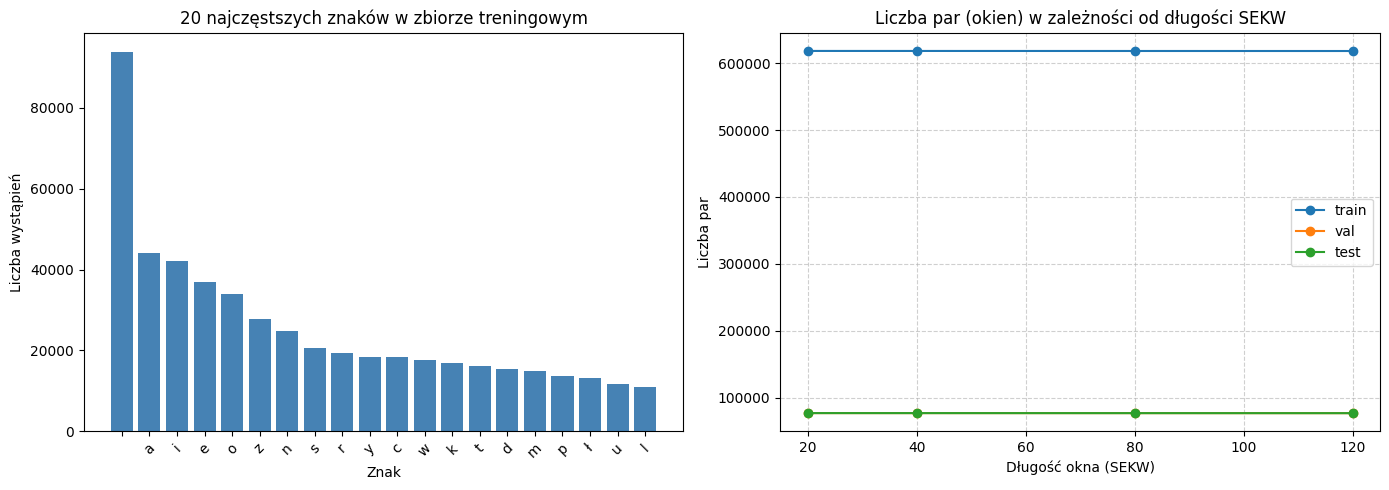

In [47]:
from collections import Counter

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
#częstość 20 najczęstszych znaków w zbiorze treningowym
licznik_znakow = Counter(tekst_train).most_common(20)
etykiety = [repr(z)[1:-1] if z in (' ', '\n', '\t') else z for z, _ in licznik_znakow]
wartosci = [c for _, c in licznik_znakow]
axes[0].bar(etykiety, wartosci, color='steelblue')
axes[0].set_title('20 najczęstszych znaków w zbiorze treningowym')
axes[0].set_xlabel('Znak')
axes[0].set_ylabel('Liczba wystąpień')
axes[0].tick_params(axis='x', rotation=45)

#liczba par w zależności od SEKW w trzech zbiorach
for nazwa in ['train', 'val', 'test']:
    axes[1].plot(df_sekw['SEKW'], df_sekw[nazwa], marker='o', label=nazwa)

axes[1].set_title('Liczba par (okien) w zależności od długości SEKW')
axes[1].set_xlabel('Długość okna (SEKW)')
axes[1].set_ylabel('Liczba par')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()